# AutoML — AutoGluon 으로 고객 이탈 예측 자동화

수업 필기 `AutoGluon` 을 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `머신러닝` v6 p.121~127 — 15. AutoML)

- 원본에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다.
- 데이터는 어제([Day 026](../../2026-10-15/)) 로지스틱 회귀 · SVM · 결정 트리로 직접 풀었던 **통신사 고객 이탈 데이터**와 같습니다 → 사람이 만든 모델과 AutoML 을 비교합니다.

> 실습 데이터 `Telco-Customer-Churn.csv` (7,043행 × 21열) 는 이 노트북과 **같은 폴더**에 있어야 합니다.
>
> 설치 : `pip install -U "autogluon.tabular[all]>=1.6.0"` (교재 p.126) · 학습에 약 **5분**(`time_limit=300`) 걸립니다.

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. AutoML 이란 (교재 p.122~124)

- **개념** : 머신러닝 모델을 만들 때 필요한 반복적이고 복잡한 과정(전처리 → 모델 선택 → 성능 고도화)을 **자동화**하는 기술
- **필요성** : 모델 개발 시간을 크게 줄여 분석가가 **비즈니스 가치**(어떤 고객을 붙잡을지 등)에 집중
- **AutoGluon** : Amazon 이 만든 **파이썬 오픈소스** AutoML 라이브러리 — 몇 줄의 코드로 전문가 수준(SOTA) 성능

| 구분 | 전통적 방식 (어제 Day 026) | AutoGluon |
|---|---|---|
| 모델 탐색 | 모델마다 코드 작성 (LR · SVC · 트리 …) | **한 줄**로 수십 개 모델 동시 학습 · 비교 |
| 데이터 전처리 | 인코딩 · 누락 · 스케일링 직접 | **기초 전처리 자동** (도메인 파생 변수 · 노이즈 정제는 여전히 사람 몫) |
| 성능 고도화 | `GridSearchCV` 등으로 하이퍼파라미터 직접 | 하이퍼파라미터 · **다층 스태킹 앙상블 자동** |

### 3-Step 워크플로우 (교재 p.125)

1. `TabularPredictor(...)` — 모델 생성 (정답 컬럼 · 평가 지표 · 저장 위치)
2. `.fit(...)` — 학습 및 최적화, **best 모델** 선택
3. `.evaluate(...)` — best 모델로 **예측 + 평가를 한 번에**

## 2. 데이터 불러오기 · 누락 처리

어제와 같은 전처리. **AutoGluon 은 문자열 컬럼을 알아서 인코딩**하므로 `get_dummies` · `map` · 스케일링이 필요 없다.

In [2]:
import pandas as pd
import warnings
warnings.filterwarnings('ignore')        # 경고는 실행 '전에' 꺼야 효과가 있다

# 데이터 불러오기 (노트북과 같은 폴더)
df = pd.read_csv('./Telco-Customer-Churn.csv')
print(df.shape)

# TotalCharges : 공백 ' ' 이 섞여 문자열로 읽힘 → 숫자로 바꿀 수 없는 값은 NaN (errors='coerce')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("TotalCharges 누락 :", df['TotalCharges'].isna().sum(), "건")

df1 = df.dropna(ignore_index=True)            # 누락 행 제거 : 7,043 -> 7,032행
df2 = df1.drop(columns=['customerID'])        # 고객 ID 는 예측에 쓸모없는 컬럼
print(df2.shape)
df2.head()

(7043, 21)
TotalCharges 누락 : 11 건
(7032, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. 학습용 · 평가용 분할 — X, y 로 나누지 않는다

scikit-learn 은 `X`(특성) 와 `y`(정답)를 따로 넣었지만, AutoGluon 은 **정답 컬럼이 들어 있는 표 그대로** 넣고 `label='Churn'` 으로 정답 컬럼 이름만 알려 준다.

In [3]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df2,
    test_size=0.2,
    random_state=0,
    stratify=df2['Churn']        # 이탈 비율(26.6%)을 학습용 · 평가용에 똑같이
)

print("학습용 :", train_df.shape, " 평가용 :", test_df.shape)

# stratify 확인 : 두 데이터의 이탈 비율이 같아야 한다
ratio = pd.DataFrame({'학습용': train_df['Churn'].value_counts(normalize=True),
                      '평가용': test_df['Churn'].value_counts(normalize=True)}).round(3)
ratio

학습용 : (5625, 20)  평가용 : (1407, 20)


,학습용,평가용
Churn,,
No,0.734,0.734
Yes,0.266,0.266


> 어제 노트북과 **같은 `random_state=0` · `stratify` · 같은 행 순서**라 평가용 1,407명이 **어제와 똑같은 고객**이다 → 결과를 그대로 비교할 수 있다.

## 4. 학습 — `TabularPredictor` → `fit` (교재 p.126~127)

| 인자 | 값 | 의미 |
|---|---|---|
| `label` | `'Churn'` | 정답 컬럼 이름 |
| `eval_metric` | `'accuracy'` | best 모델을 고르는 기준 (`'f1'`, `'roc_auc'` 등도 가능) |
| `path` | `'AutoGluon_Model'` | 학습된 모델을 **저장할 폴더** |
| `presets` | `'best_quality'` | 시간이 걸려도 **최고 성능** 설정 (배깅 + 스태킹) |
| `num_gpus` | `0` | CPU 만 사용 |
| `dynamic_stacking` | `False` | 스태킹 층 수를 미리 시험해 보는 **사전 탐색(DyStack)** 을 끔 → 시간 절약 |
| `num_stack_levels` | `1` | 1층 모델들 위에 **스태킹 층을 1개** 더 쌓음 |
| `time_limit` | `300` | 전체 학습 시간 제한 **300초(5분)** |

In [4]:
from autogluon.tabular import TabularPredictor

# 1. 모델 생성
predictor = TabularPredictor(label='Churn', eval_metric='accuracy', path='AutoGluon_Model')

# 2. 학습 및 최적화, best 모델 생성 (약 5분)
predictor.fit(
    train_data=train_df,
    presets='best_quality',
    num_gpus=0,
    dynamic_stacking=False,
    num_stack_levels=1,
    time_limit=300
)

Verbosity: 2 (Standard Logging)
	Failed to import torch or check CUDA availability!Please ensure you have the correct version of PyTorch installed by running `pip install -U torch`
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.16
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP PREEMPT_DYNAMIC @0
CPU Count:          2
Pytorch Version:    Can't import torch
CUDA Version:       Can't get cuda version from torch
Memory Avail:       6.89 GB / 7.84 GB (87.8%)
Disk Space Avail:   27.06 GB / 251.97 GB (10.7%)
Presets specified: ['best_quality']
Using hyperparameters preset: hyperparameters='zeroshot'
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
Beginning AutoGluon training ... Time limit = 300s
AutoGluon will save models to "/tmp/claude-0/-home-claude/fdec0e98-0437-5359-b4b1-6046e5d2ed95/scratchpad/x27/AutoGluon_Model"
Train Data Rows:    5625
Train Data Column

> **📝 고친 부분** (`AutoGluon`)
> - 변수 이름 `predicter` → `predictor` (영어 철자)
> - 데이터 경로 `C:\\Users\\...\\Telco-Customer-Churn.csv` → 노트북과 같은 폴더 `./Telco-Customer-Churn.csv`
> - 누락 처리 셀에서 `display(df1)` 로 **`customerID` 가 남아 있는 표**를 확인 → 실제 학습에 쓰는 `df2` 를 확인하도록 변경
> - `train_df_ratin = ...value_counts(...)` 는 오타 + 만들기만 하고 출력하지 않음 → 학습용 · 평가용 이탈 비율 비교표로 출력
> - `warnings.filterwarnings('ignore')` 가 `evaluate()` **뒤에** 있어서 효과가 없었음 → 맨 앞으로

## 5. 리더보드 — 어떤 모델들을 만들었나

`best_quality` 는 모델 하나하나를 **배깅(BAG, 학습용을 8조각으로 나눠 교차 검증)** 으로 학습하고(L1), 그 예측값을 다시 특성으로 쓰는 **스태킹 층(L2)** 을 쌓은 뒤, 마지막에 **가중 평균(WeightedEnsemble)** 으로 합친다 — [Day 025](../../2026-10-14/) 의 배깅 · 스태킹이 자동으로 일어나는 것.

| 이름 규칙 | 의미 |
|---|---|
| `_BAG_L1` | 1층 : 원본 특성으로 학습한 배깅 모델 |
| `_BAG_L2` | 2층 : 원본 특성 + **1층 모델들의 예측값**으로 학습 (스태킹) |
| `WeightedEnsemble_L2 / L3` | 바로 아래 층 모델들의 **가중 평균** |
| `score_val` | 학습용 안에서 떼어 둔 검증 점수 (평가용은 아직 안 씀) |

In [5]:
leaderboard = predictor.leaderboard()
leaderboard[['model', 'score_val', 'fit_time', 'stack_level']]

,model,score_val,fit_time,stack_level
0,LightGBM_BAG_L2,0.813156,123.416137,2
1,WeightedEnsemble_L3,0.813156,123.767425,3
2,XGBoost_BAG_L2,0.813156,125.522487,2
3,CatBoost_BAG_L2,0.812800,169.233649,2
4,LightGBMLarge_BAG_L2,0.809600,132.959192,2
5,LightGBMXT_BAG_L2,0.809244,124.023369,2
6,CatBoost_r137_BAG_L1,0.808889,15.628549,1
7,WeightedEnsemble_L2,0.808889,15.881402,2
8,CatBoost_r13_BAG_L1,0.808889,10.644522,1
9,RandomForestEntr_BAG_L2,0.808178,119.961038,2


In [6]:
# best 모델 (score_val 이 가장 높은 모델, 같으면 예측이 빠른 쪽)
print("best 모델 :", predictor.model_best)

best 모델 : WeightedEnsemble_L3


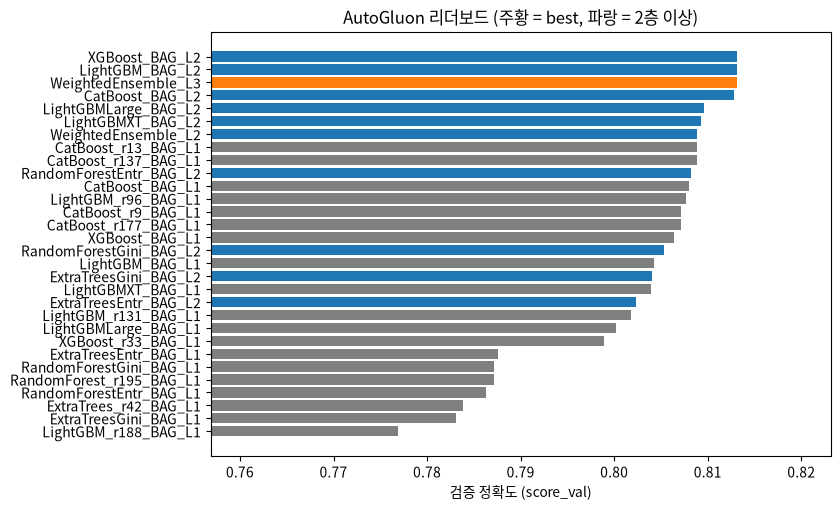

In [7]:
# 리더보드를 막대 그래프로
lb = leaderboard.sort_values('score_val')
colors = ['tab:orange' if m == predictor.model_best else
          ('tab:blue' if s == 2 else 'tab:gray') for m, s in zip(lb['model'], lb['stack_level'])]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(lb['model'], lb['score_val'], color=colors)
ax.set_xlim(lb['score_val'].min() - 0.02, lb['score_val'].max() + 0.01)
ax.set_xlabel('검증 정확도 (score_val)')
ax.set_title('AutoGluon 리더보드 (주황 = best, 파랑 = 2층 이상)')
plt.show()

![AutoGluon 리더보드](./images/06_autogluon_leaderboard.png)

| | 수업 실행 (필기 출력) | 다시 실행 (정리하면서) |
|---|---|---|
| 학습된 모델 수 | 15개 | 30개 |
| best 모델 | `WeightedEnsemble_L3` (검증 0.8123) | `WeightedEnsemble_L3` (검증 0.8132) |
| 1층 최고 | `CatBoost_BAG_L1` (0.8078) | `CatBoost_r137_BAG_L1` (0.8089) |

- 1층보다 2층(스태킹) 모델들이 대체로 높다 → 스태킹이 효과가 있었다.
- AutoGluon 은 **실행할 때마다 · 컴퓨터마다 결과가 조금씩 다르다** — `time_limit` 안에 몇 개의 모델을 학습하느냐가 컴퓨터 속도에 따라 달라지기 때문. 신경망(`NeuralNetFastAI`)은 `torch` 가 설치돼 있어야 학습되고(다시 실행한 환경에는 없어서 빠짐), 대신 `XGBoost` · `LightGBM_r96` 처럼 하이퍼파라미터를 바꾼 모델들이 더 학습됐다.

## 6. 평가 — `evaluate()` 한 번에 예측 + 평가 (교재 p.127)

In [8]:
# 3. best 모델 성능 평가 (평가용 데이터 : 정답 컬럼이 들어 있는 표 그대로)
performance = predictor.evaluate(test_df)

for name, value in performance.items():
    print(f"{name:>18} : {float(value):.4f}")

          accuracy : 0.8138
 balanced_accuracy : 0.7069
               mcc : 0.4812
           roc_auc : 0.8473
                f1 : 0.5774
         precision : 0.7276
            recall : 0.4786


| 지표 | 의미 |
|---|---|
| `accuracy` | 전체 중 맞힌 비율 |
| `balanced_accuracy` | **정답별(유지 · 이탈) 정확도를 따로 구해 평균** — 불균형 데이터에서 정확도의 착시를 막는다 |
| `precision` · `recall` · `f1` | **이탈(Yes)** 을 양성으로 본 정밀도 · 재현율 · F1 |
| `roc_auc` | 임계값과 관계없이 이탈 / 유지 고객을 **확률로 얼마나 잘 줄 세우는지** (1 = 완벽, 0.5 = 무작위) |
| `mcc` | 혼동 행렬 4칸을 모두 반영한 상관계수 (-1 ~ 1) |

> **📝 고친 부분** — `balanced_accuracy` 주석
> 필기의 예 "accuracy(이탈 X) = 100%, accuracy(이탈 O) = 0%, 평균 1 + 0 / 2" → 괄호가 빠져 `1 + 0/2 = 1` 로 읽힌다. **`(1 + 0) / 2 = 0.5`**.
> 즉 **전부 "유지"라고 찍는 모델**은 accuracy 는 0.734 지만 balanced accuracy 는 **0.5** — 어제 스케일링 안 한 SVC 가 바로 이 경우였다.

In [9]:
# evaluate() 는 내부에서 predict() + 점수 계산을 한 것 — 직접 해 보면 같은 값
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score

y_pred = predictor.predict(test_df)
print("accuracy          :", round(accuracy_score(test_df['Churn'], y_pred), 4))
print("balanced_accuracy :", round(balanced_accuracy_score(test_df['Churn'], y_pred), 4))
print("recall (Yes)      :", round(recall_score(test_df['Churn'], y_pred, pos_label='Yes'), 4))

# 전부 'No' 라고 찍은 경우
all_no = ['No'] * len(test_df)
print("\n[전부 'No'] accuracy :", round(accuracy_score(test_df['Churn'], all_no), 4),
      "/ balanced :", balanced_accuracy_score(test_df['Churn'], all_no))

accuracy          : 0.8138
balanced_accuracy : 0.7069
recall (Yes)      : 0.4786

[전부 'No'] accuracy : 0.7342 / balanced : 0.5


## 7. 저장된 모델 불러오기

`fit` 이 끝나면 `path` 폴더(`AutoGluon_Model/`)에 모델이 **자동 저장**된다. 다음에는 다시 5분 학습할 필요 없이 불러와서 바로 쓴다.

In [10]:
# 저장된 모델(학습이 끝난 상태) 불러오기 — 노트북 기준 상대 경로
loaded_predictor = TabularPredictor.load('AutoGluon_Model')

performance_loaded = loaded_predictor.evaluate(test_df)
print("저장된 모델로 평가 :", round(float(performance_loaded['accuracy']), 4))
print("방금 학습한 모델과 같은가? :", performance_loaded['accuracy'] == performance['accuracy'])

저장된 모델로 평가 : 0.8138
방금 학습한 모델과 같은가? : True


> **📝 고친 부분** — 모델 경로 `C:\\Users\\...\\AutoGluon_Model` → `'AutoGluon_Model'` (어느 컴퓨터에서나 동작)
>
> ⚠️ `AutoGluon_Model/` 폴더는 수백 MB 가 될 수 있어 **GitHub 에는 올리지 않았다**.

## 8. 사람(어제) vs AutoML(오늘) — 같은 평가용 1,407명

| 모델 | 정확도 | 재현율(이탈) | F1 | 만든 방법 |
|---|---|---|---|---|
| 기준선 (전부 "유지") | 0.734 | 0 | 0 | — |
| LogisticRegression (스케일링) | **0.808** | **0.554** | **0.605** | Day 026 직접 |
| SVC (스케일링) | 0.797 | 0.471 | 0.553 | Day 026 직접 |
| DecisionTree (`max_depth=3`) | 0.795 | 0.390 | 0.503 | Day 026 직접 |
| **AutoGluon** `WeightedEnsemble_L3` (수업 실행) | 0.803 | 0.457 | 0.553 | 5분 자동 |
| **AutoGluon** `WeightedEnsemble_L3` (다시 실행) | **0.814** | 0.479 | 0.577 | 5분 자동 |

- 5분 · 코드 몇 줄로 **0.803 ~ 0.814** — 직접 튜닝한 모델들과 같은 수준까지 **자동으로** 올라갔다.
- 하지만 잘 전처리한 **로지스틱 회귀(0.808)와 ±0.6%p 안** — 실행에 따라 이기기도 지기도 한다. 특성이 적고 관계가 단순한 데이터에서는 단순한 모델로 충분할 때가 많다(학습 5분 · 모델 폴더 약 600MB vs 1초 · 몇 KB).
- AutoGluon 도 `eval_metric='accuracy'` 로 골랐기 때문에 재현율이 낮다. 이탈 고객을 놓치지 않는 게 목적이면 `eval_metric='f1'` 또는 `'recall'` · `'balanced_accuracy'` 로 다시 학습한다.

### 특성 중요도 — 평가용 데이터에서 컬럼 하나씩 섞어 보기

In [11]:
# 컬럼 하나의 값을 무작위로 섞었을 때 정확도가 얼마나 떨어지는지 (permutation importance, 1~2분)
fi = predictor.feature_importance(test_df)
fi[['importance', 'stddev']].head(10)

Computing feature importance via permutation shuffling for 19 features using 1407 rows with 5 shuffle sets...
	249.19s	= Expected runtime (49.84s per shuffle set)
	57.86s	= Actual runtime (Completed 5 of 5 shuffle sets)


,importance,stddev
tenure,0.042502,0.006060
Contract,0.040654,0.005997
InternetService,0.023738,0.002869
MonthlyCharges,0.017200,0.003460
TotalCharges,0.014641,0.001078
OnlineSecurity,0.010803,0.005352
PaperlessBilling,0.009524,0.001920
TechSupport,0.009240,0.006397
MultipleLines,0.008102,0.002734
OnlineBackup,0.007676,0.001770


`tenure`(가입 기간) · `Contract`(계약 형태) 가 1 · 2위 — 어제 결정 트리의 특성 중요도 1위(월 단위 계약)와 같은 이야기를 한다.

### 정리

- AutoML 은 **모델 선택 · 하이퍼파라미터 · 앙상블**을 자동화하지만, **누락 처리 · 쓸모없는 컬럼 제거 · 평가 지표 선택**은 여전히 사람이 결정한다.
- `evaluate()` 의 여러 지표 중 **불균형 데이터에서는 accuracy 만 보지 말 것** (`balanced_accuracy` · `recall` · `f1`).
- 사람이 만든 기준 모델(로지스틱 회귀 등)과 **꼭 비교**해서 AutoML 이 정말 이득인지 확인한다.